# Mini Proj-4 — Student Performance in the Department

**Instructions to students**

1. Do not delete or create cells.
2. Solve all questions and don't leave any questions empty.
3. Rename the Lab to `Mini_Proj_4_StudentID`, changing `StudentID` to your actual student ID.
4. **Make sure to write correct variable names — it has marks.**
5. Keep `student_performance.csv` in the same folder as this notebook.
6. The questions build on each other: you clean the table in Q2 (`clean`) and the questions after it use it. Do the questions in order.
7. Every chart needs the title and labels the question gives, and must be shown with `plt.show()`.
8. Where a question asks you to print, do it — printing is not marked, but it lets you check your own answers.
9. **Three questions are written (they are called W1, W2 and W3).** Each has an **empty code cell** under its question. Write your answer in that cell **as comments**: every line of your answer starts with `#`. Write one or two sentences and mention your numbers. The computer does not check these answers; your instructor reads them and marks them by hand.

**The story:** The department offers AI and CS programs. Before trying to explain causes or predict results, we want to **describe** how our students performed: the typical score, how spread out the scores are, and which study habits go together with the exam score. The file `student_performance.csv` holds one row per student.

| Column | Meaning |
|---|---|
| `Student_ID` | Student number |
| `Program` | `AI` or `CS` |
| `Study_Hours` | Hours of study per week |
| `Attendance_Pct` | Attendance, in percent |
| `Sleep_Hours` | Average hours of sleep |
| `Previous_Grade` | Grade in the previous course |
| `Screen_Time_Hours` | Hours of screen time per day |
| `Practice_Hours` | Hours of practice per week |
| `Study_Shift_Hours` | How many hours the study time moved away from the plan |
| `Routine_Disruption` | Index of how much the routine was disturbed |
| `Exam_Score` | Exam score |

*All records are synthetic. Two columns (`Study_Shift_Hours` and `Routine_Disruption`) were built to show one idea in Q7. Associations in this data do not prove that one thing causes another.*


## Part 0 — Setup (0 marks)

Import the libraries you'll need for this project, and print the versions of numpy and pandas.


In [25]:
# TODO (0.1): Import numpy as np, pandas as pd, matplotlib.pyplot as plt and seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# TODO (0.2): Print the version of numpy, then the version of pandas
# === Write your answer here: ===
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.4.6
Pandas version: 3.0.6


## Part 1 — Load, inspect and clean (8 marks)

**Before we trust a dataset, we look at what it contains and whether it is complete.**

---

### Q1 — Load and inspect the data (4 marks)

Read the file and check it: the summary statistics, the **missing values**, and the **repeated students** (`Student_ID` should be unique).


In [26]:
# TODO (1.1): Read student_performance.csv into a DataFrame -> raw
# TODO (1.2): Get the summary statistics of the numeric columns of raw, rounded to 2 decimal places -> summary
# TODO (1.3): Count the missing values in every column of raw -> missing_per_column
# TODO (1.4): Count the rows of raw whose Student_ID already appeared in an earlier row -> n_duplicate_ids
# TODO (1.5): Print summary, missing_per_column and n_duplicate_ids

# === Write your answer here: ===
raw = pd.read_csv('student_performance.csv')
summary = raw.describe().round(2)
missing_per_column = raw.isnull().sum()
n_duplicate_ids = raw.duplicated(subset=['Student_ID']).sum()

print("Summary statistics:")
print(summary)
print("\nMissing values per column:")
print(missing_per_column)
print("\nNumber of duplicate Student_IDs:")
print(n_duplicate_ids)

Summary statistics:
       Study_Hours  Attendance_Pct  Sleep_Hours  Previous_Grade  \
count       181.00          180.00       180.00          180.00   
mean          8.35           77.48         7.03           71.43   
std           5.66           11.99         0.89           11.96   
min           3.60           45.00         4.70           43.00   
25%           6.90           68.00         6.40           63.75   
50%           8.00           78.00         7.00           71.00   
75%           9.00           86.00         7.70           80.00   
max          80.00          100.00         9.50           98.00   

       Screen_Time_Hours  Practice_Hours  Study_Shift_Hours  \
count             180.00          180.00             181.00   
mean                4.37            6.37               0.01   
std                 1.66            1.51               2.58   
min                 0.50            2.80              -4.00   
25%                 3.20            5.50              -2.00  

---

### Q2 — Clean the data (4 marks)

The data has problems: a repeated student, a student **without an exam score**, and one student with **80** study hours (the highest of all, a typing error for **8** hours in this synthetic data).

This project uses the following cleaning policy. Follow the steps **in this order**, on a **copy** of `raw` (`raw` must stay as it was read):

1. Remove the repeated `Student_ID` rows (keep the first one of each student).
2. Remove the rows whose `Exam_Score` is missing.
3. Change the 80 study hours into 8.
4. Fill the missing values of the eight input columns `Study_Hours`, `Attendance_Pct`, `Sleep_Hours`, `Previous_Grade`, `Screen_Time_Hours`, `Practice_Hours`, `Study_Shift_Hours` and `Routine_Disruption` with the **median** of each column.

*(This is a classroom policy, not a universal cleaning rule. In real work you would check the 80 with the source before changing it.)*


In [27]:
# TODO (2.1): Make a copy of raw without the repeated Student_ID rows and without the rows that have no Exam_Score -> clean
# TODO (2.2): In clean, change the Study_Hours value 80 into 8
# TODO (2.3): In clean, fill the missing values of the eight input columns with the median of each column
# TODO (2.4): Print the number of rows of clean and the total number of missing values left in clean

# === Write your answer here: ===
clean = (raw.drop_duplicates(subset=['Student_ID']).dropna(subset=['Exam_Score']).copy())
clean.loc[clean['Study_Hours'] == 80, 'Study_Hours'] = 8

inputs = ["Study_Hours", "Attendance_Pct", "Sleep_Hours", "Previous_Grade",
          "Screen_Time_Hours", "Practice_Hours", "Study_Shift_Hours",
          "Routine_Disruption"]
for col in inputs:
    clean[col] = clean[col].fillna(clean[col].median())

print("Number of rows in clean:", len(clean))
print("Total number of missing values in clean:", clean.isnull().sum().sum())

Number of rows in clean: 179
Total number of missing values in clean: 0


## Part 2 — The center and the spread (14 marks)

**What is a typical exam score? How do the average, the middle and the most frequent score differ? Do AI and CS students have similar averages but different spread?**

---

### Q3 — The typical score (4 marks)

From now on use the table `clean`. Calculate the three measures of center of the exam scores and draw their **distribution**.

The **mode** is the most frequent score. Store it as **one number** (if several scores are equally frequent, the smallest).


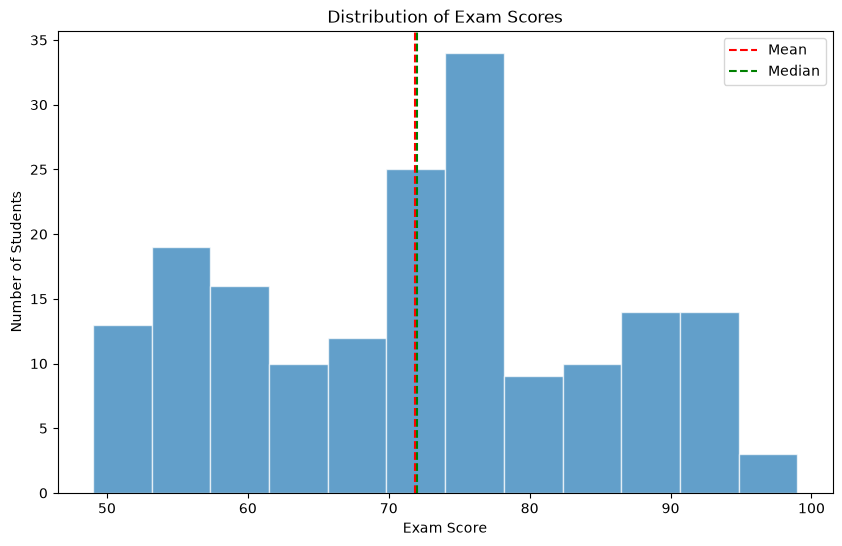

Mean: 71.87
Median: 72.00
Mode: 76.00


In [28]:
# TODO (3.1): Store the Exam_Score column of clean -> scores
scores = clean['Exam_Score']
# TODO (3.2): Calculate the mean, the median and the mode of scores -> mean_score, median_score, mode_score
mean_score = scores.mean()
median_score = scores.median()
mode_score = scores.mode().min()
# TODO (3.3): Draw a histogram of scores with 12 bins and white bar edges, with a red dashed vertical line at the mean (label "Mean") and a green dashed vertical line at the median (label "Median")
plt.figure(figsize=(10, 6))
plt.hist(scores, bins=12, edgecolor='white', alpha=0.7)
plt.axvline(mean_score, color='red', linestyle='--', label='Mean')
plt.axvline(median_score, color='green', linestyle='--', label='Median')
# TODO (3.4): Give the chart the title "Distribution of Exam Scores", the x label "Exam Score", the y label "Number of Students" and a legend, and show it using plt.show()
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.legend()
plt.show()
# TODO (3.5): Print mean_score (rounded to 2 decimal places), median_score and mode_score
# === Write your answer here: ===
print(f"Mean: {mean_score:.2f}")
print(f"Median: {median_score:.2f}")
print(f"Mode: {mode_score:.2f}")


---

### Q4 — Extreme scores (4 marks)

How much do the lowest and the highest scores pull the mean and the median? They are **real students**: do not delete them from `clean`; only leave them out for this comparison.

Sort the scores from lowest to highest, then compare.


In [29]:
# TODO (4.1): From scores, make the scores without the 3 lowest -> without_low3, and the scores without the 3 highest -> without_high3
# TODO (4.2): Calculate the mean and the median of each of them -> mean_no_low, median_no_low, mean_no_high, median_no_high
# TODO (4.3): Print mean_no_low, median_no_low, mean_no_high and median_no_high (rounded to 2 decimal places)
# === Write your answer here: ===
sorted_scores = scores.sort_values()
without_low3 = sorted_scores.iloc[3:]
without_high3 = sorted_scores.iloc[:-3]

mean_no_low = without_low3.mean()
median_no_low = without_low3.median()
mean_no_high = without_high3.mean()
median_no_high = without_high3.median()

print(f"Mean without lowest 3: {mean_no_low:.2f}")
print(f"Median without lowest 3: {median_no_low:.2f}")
print(f"Mean without highest 3: {mean_no_high:.2f}")
print(f"Median without highest 3: {median_no_high:.2f}")


Mean without lowest 3: 72.24
Median without lowest 3: 72.50
Mean without highest 3: 71.45
Median without highest 3: 72.00


---

### Q5 — AI versus CS: the spread (4 marks)

Compare the two programs with the same measurements. The **standard deviation** is the sample standard deviation (the pandas default). The **IQR** is the 75th percentile minus the 25th percentile (use `quantile`). Then show the spread with a **box plot** (the box is the middle 50% of the scores).


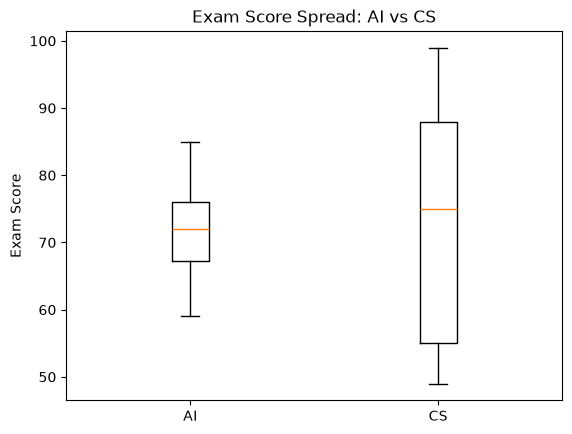

71.63 5.76 8.75
72.1 17.11 33.0


In [30]:
# TODO (5.1): Store the Exam_Score of the AI students of clean -> ai, and the Exam_Score of the CS students -> cs
# TODO (5.2): Calculate the mean, the standard deviation and the IQR of each -> ai_mean, ai_sd, ai_iqr, cs_mean, cs_sd, cs_iqr
# TODO (5.3): Draw a box plot of ai and cs side by side, with the labels "AI" and "CS" under the boxes
# TODO (5.4): Give the chart the title "Exam Score Spread: AI vs CS" and the y label "Exam Score", and show it using plt.show()
# TODO (5.5): Print the six values of 5.2
# === Write your answer here: ===

ai = clean.loc[clean['Program'] == 'AI', 'Exam_Score']
cs = clean.loc[clean['Program'] == 'CS', 'Exam_Score']

ai_mean = ai.mean()
ai_sd = ai.std()
ai_iqr = ai.quantile(0.75) - ai.quantile(0.25)
cs_mean = cs.mean()
cs_sd = cs.std()
cs_iqr = cs.quantile(0.75) - cs.quantile(0.25)

plt.boxplot([ai, cs])
plt.xticks([1, 2], ['AI', 'CS'])

plt.title("Exam Score Spread: AI vs CS")
plt.ylabel("Exam Score")
plt.show()

print(round(ai_mean, 2), round(ai_sd, 2), round(ai_iqr, 2))
print(round(cs_mean, 2), round(cs_sd, 2), round(cs_iqr, 2))


### W1 — Written: the typical score and the spread (2 marks, marked by hand)

**Which is more representative of the typical exam score here, the mean or the median, and why? How do AI and CS differ in spread and in the shape of their scores?**

Write your answer in the **empty code cell below, as comments** (every line starts with `#`), in one or two sentences, with your numbers.


In [31]:
# === Write your answer here: ===
# The mean (71.87) and the median (72.00) are almost the same, so both describe the typical score well, but I prefer the median (72.00) because it is not affected by extreme scores by design.
# Removing the 3 lowest scores changed the mean from 71.87 to 72.24 and the median from 72.00 to 72.50; removing the 3 highest changed the mean to 71.45 and the median stayed 72.00, so the changes are small and the scores are roughly symmetric.
# AI and CS have almost the same mean (71.63 and 72.10), but CS is much more spread out (SD 17.11 vs 5.76, IQR 33.0 vs 8.75), so AI scores are close to each other while CS has very low and very high scores.

## Part 3 — Relationships between variables (12 marks)

**Which study-related variables go together? The Pearson correlation `r` measures the direction and strength of a *linear* association.**

---

### Q6 — Study hours and exam score (4 marks)

Do students who study more tend to score higher? Calculate the correlation and draw it.


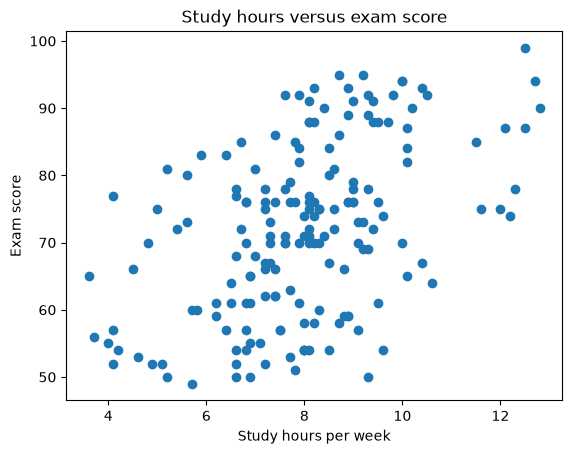

0.48


In [32]:
# TODO (6.1): Calculate the Pearson correlation between the Study_Hours column and the Exam_Score column of clean -> study_r
# TODO (6.2): Draw a scatter plot of Study_Hours (x axis) against Exam_Score (y axis), with the title "Study hours versus exam score", the x label "Study hours per week" and the y label "Exam score", and show it using plt.show()
# TODO (6.3): Print study_r rounded to 3 decimal places
# === Write your answer here: ===
study_r = clean['Study_Hours'].corr(clean['Exam_Score'])

plt.scatter(clean['Study_Hours'], clean['Exam_Score'])
plt.title("Study hours versus exam score")
plt.xlabel("Study hours per week")
plt.ylabel("Exam score")
plt.show()


print(round(study_r, 3))


---

**Before you submit:** read every question once more, check that every variable has exactly the name the question gives, that every chart has its title and labels, and that your notebook runs from the first cell to the last without errors. Remember that your written answers (W1) must be comments: every line starts with `#`.
